# Fraud Detection: A Reproducible Study

This notebook explains the analysis and loads generated outputs. Expensive fitting is kept in scripts; cached results make this notebook quick to run.

## Contents

- Data and chronological evaluation
- Why imbalance changes the metric choice
- Leakage-safe models and resampling
- EDA findings and decisions
- Cross-validation and final evaluation
- Explainability, cost sensitivity, and v1 fixes

## Goal

Establish the study inputs and find the saved audit.

## Concept

The data contains anonymized principal-component features, transaction time, amount, and a binary fraud label. Duplicate rows are removed before splits. Time is elapsed seconds from the first transaction in the file, not wall-clock time. Feature construction is deterministic and learns no statistics from validation or test data.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
DATA_PATH = ROOT / "data" / "creditcard.csv"
RUN_HEAVY = False

## What we see

The audit file is the source for row and fraud counts. If it is missing, run the audit script.

## Decision

Use contiguous chronological splits as the primary protocol.

In [2]:
AUDIT_PATH = RESULTS / "data_audit.json"
if AUDIT_PATH.exists():
    audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
    display(pd.json_normalize(audit["splits"], sep="_"))
else:
    display(Markdown("Run `python scripts/audit_data.py` to create the split audit."))

,train_rows,train_frauds,train_legitimate,train_time_min_seconds,train_time_max_seconds,validation_rows,validation_frauds,validation_legitimate,validation_time_min_seconds,validation_time_max_seconds,test_rows,test_frauds,test_legitimate,test_time_min_seconds,test_time_max_seconds
0,170235,342,169893,0.0,120392.0,56745,57,56688,120393.0,145233.0,56746,74,56672,145234.0,172792.0


## Goal

Explain why accuracy is not the headline measure.

## Concept

When fraud is rare, predicting every case as legitimate can produce high accuracy. Precision-recall curves focus on finding positive cases and the false alerts created along the way. We report average precision as the primary ranking measure, with ROC-AUC and Matthews correlation as complementary views. Alert precision at a fixed review budget connects ranking to an operational constraint.

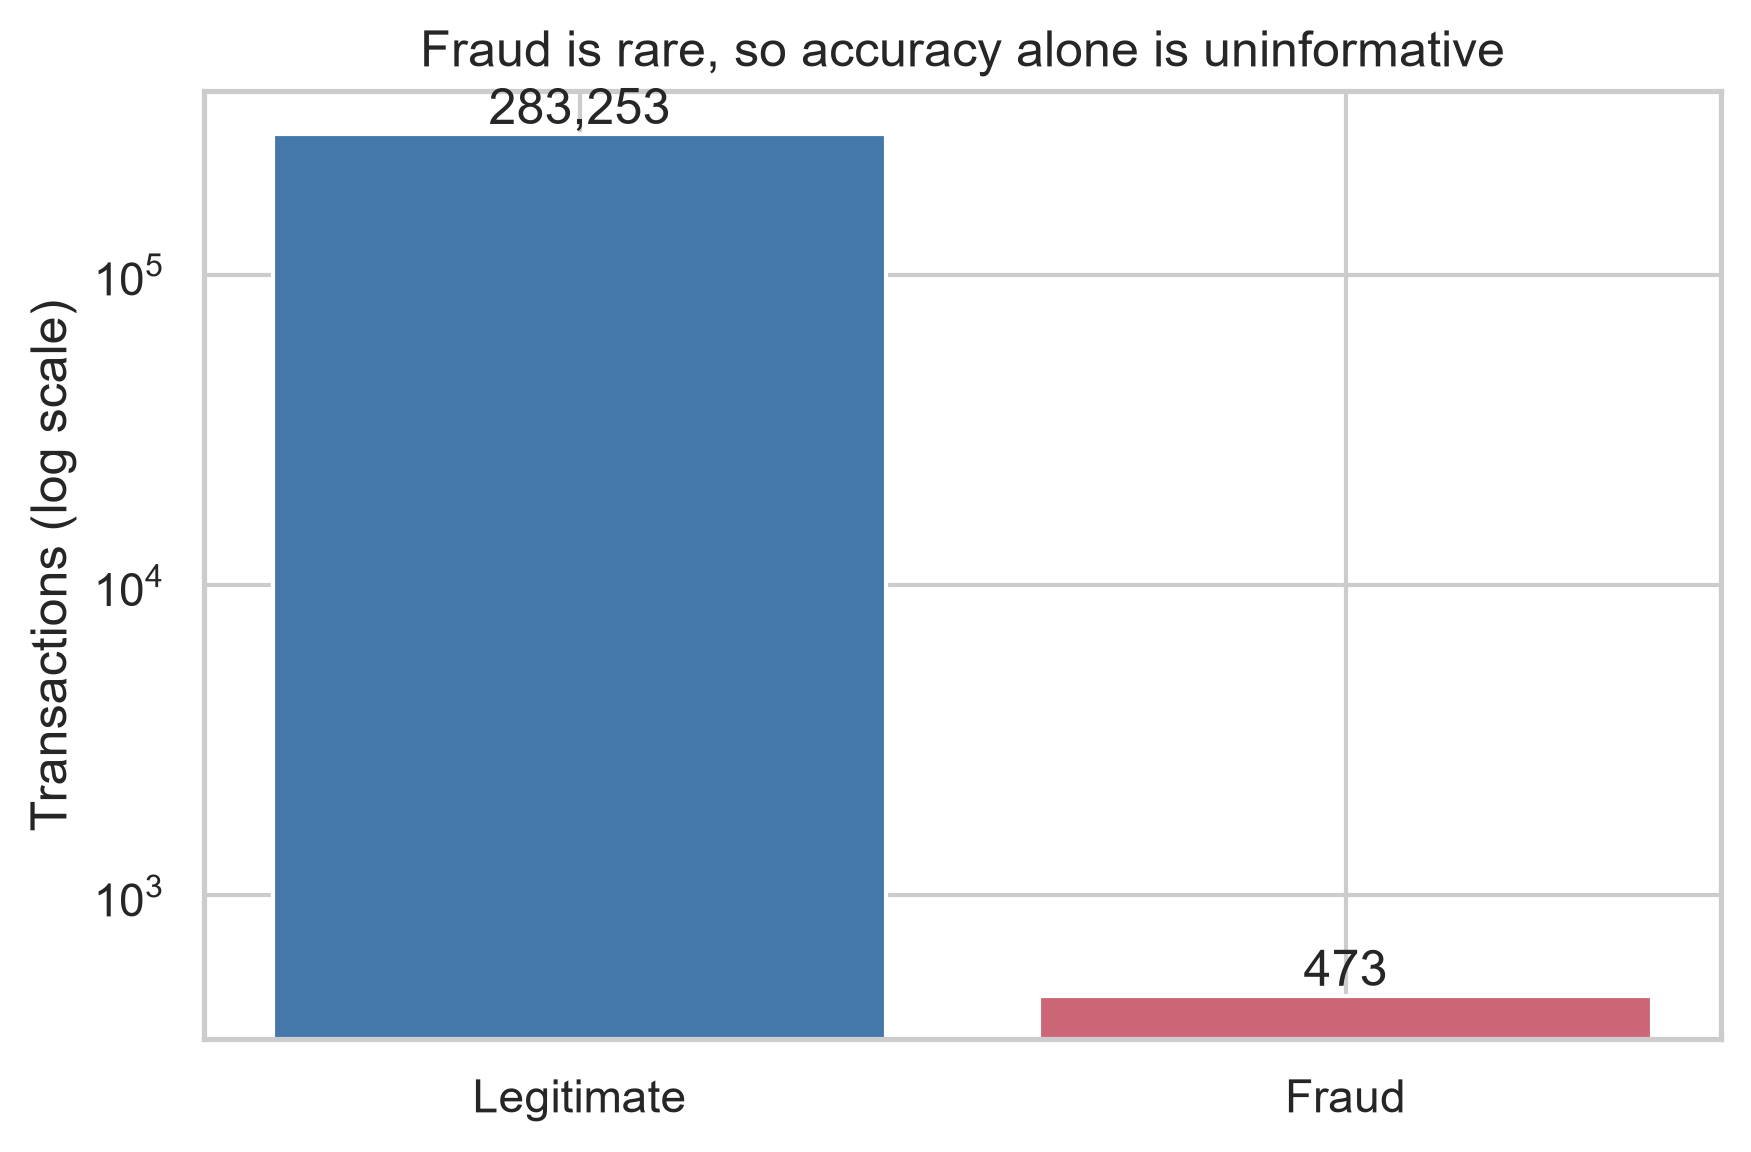

In [3]:
fig = FIGURES / "f01_class_imbalance.png"
if fig.exists(): display(Image(filename=str(fig)))

## What we see

The imbalance figure and EDA findings are generated from the audited dataset and train split.

## Decision

Keep accuracy only as a contextual baseline; do not use it to select models.

In [4]:
findings = RESULTS / "eda_findings.md"
if findings.exists(): display(Markdown(findings.read_text(encoding="utf-8")))

# EDA findings and decisions

F1 — Finding: the class distribution is highly imbalanced. Decision: report PR-AUC and alert precision/recall; accuracy is contextual only.

F2 — Finding: transaction volume and fraud rate change over the train window. Decision: preserve chronological order and include cyclical hour features.

F3 — Finding: amount distributions overlap. Decision: retain log1p(Amount) as one input among the anonymized V features.

F4 — Finding: marginal effect sizes and mutual information rank features differently. Decision: treat these screens as descriptive and verify with model-based measures.

F5 — Finding: some components separate classes marginally, but their densities overlap. Decision: compare multivariate models without claiming causal or business meaning.

Inference notes: Shapiro-Wilk is uninformative at this sample size; t-test and ANOVA are redundant for two groups; Spearman with a binary target duplicates the rank-based group comparison.


## Goal

Compare models and imbalance treatments without leaking across folds.

## Concept

Logistic regression is convex and interpretable through coefficients, but it has a linear boundary and needs scaling. Random forests capture interactions without scaling, though their vote averages can be coarse. Distance-weighted nearest neighbors provide a local reference but suffer in high dimensions and cost more at prediction time. XGBoost regularizes gradient-boosted trees and can weight classes; CatBoost uses ordered boosting, while its categorical feature machinery is irrelevant for these numeric inputs. SMOTE and undersampling operate only inside training folds because they alter the class distribution.

In [5]:
config_path = RESULTS / "config_snapshot.json"
if config_path.exists(): display(Markdown("```json\n" + config_path.read_text(encoding="utf-8") + "```"))

```json
{
  "seed": 42,
  "protocol": "chronological 60/20/20; stratified 5-fold CV on train",
  "features": ["V1..V28", "log1p_amount", "hour_sin", "hour_cos"],
  "models": {
    "lr": {"C": 1, "max_iter": 2000},
    "rf": {"n_estimators": 300, "min_samples_leaf": 2},
    "knn": {"n_neighbors": 25, "weights": "distance"},
    "xgb": {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 6, "tree_method": "hist"},
    "catboost": {"iterations": 500, "depth": 6, "learning_rate": 0.05, "task_type": "CPU"}
  },
  "strategies": ["class weights", "SMOTE", "random undersampling"],
  "status": "config specification; full cross-validation not yet run"
}
```

## What we see

Cross-validation outputs are the evidence for model selection. FAST outputs are development-only and must not be substituted for full CV.

## Decision

Prefer the strongest mean PR-AUC, using the one-standard-error rule to favor a simpler or faster option when appropriate.

In [6]:
cv_path = RESULTS / "cv_summary.csv"
if cv_path.exists():
    display(pd.read_csv(cv_path).sort_values("mean", ascending=False))
else:
    display(Markdown("Full CV has not been run. Use `python scripts/run_cv.py --models ... --strategies ...` in chunks."))

Full CV has not been run. Use `python scripts/run_cv.py --models ... --strategies ...` in chunks.

## Goal

Keep threshold choice separate from final evaluation.

## Concept

Ranking measures do not choose an operating threshold. The threshold is selected on validation data, where false alerts and missed fraud can be inspected before the final test is opened. Stratified bootstrap intervals show how uncertain the test estimates are with a small number of fraud examples. If a paired interval includes zero, the study has no evidence of a difference for that comparison.

In [7]:
metrics_path = RESULTS / "final_metrics.json"
if metrics_path.exists():
    final_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    display(pd.DataFrame(final_metrics.get("models", [])))
else:
    display(Markdown("Final test evaluation is pending the full CV model selection."))

Final test evaluation is pending the full CV model selection.

## What we see

Final metrics and confidence intervals are read from the results file; this notebook does not type or recompute headline values.

## Decision

Use the validation-selected operating point and report uncertainty alongside ranking metrics.

In [8]:
for image_name in ["f08_test_pr_curves.png", "f09_confusion_matrices.png", "f10_validation_thresholds.png"]:
    image_path = FIGURES / image_name
    if image_path.exists(): display(Image(filename=str(image_path)))

## Goal

Describe model behavior and the limits of operational interpretation.

## Concept

Permutation importance measures how validation performance changes when a feature is shuffled. SHAP decomposes a model score into feature contributions. Neither explains why a person committed fraud, and the PCA components have no direct merchant or customer meaning. Review-cost curves are illustrative sensitivity analyses because no actual review cost or recovery process was supplied.

In [9]:
for image_name in ["f11_reliability.png", "f13_cost_sensitivity.png", "f14_explainability_errors.png"]:
    image_path = FIGURES / image_name
    if image_path.exists(): display(Image(filename=str(image_path)))

## Mistakes in v1 and how v2 fixes them

| v1 issue | v2 correction |
|---|---|
| Scaling before splitting | Fit scaling inside each training-fold pipeline |
| Threshold chosen on test | Choose threshold on validation |
| Model selected by test score | Select by train-only cross-validation |
| Duplicated training paths and hand-entered metrics | One scripts-to-results path |
| One random split and a small positive test count | Chronological holdout, cross-validation, and bootstrap uncertainty |
| Random split ignores order | Preserve order for the primary protocol |
| Resampling outside folds | Resample only in the training pipeline |
| Raw elapsed time | Cyclical hour features; remove raw Time from predictors |
| Shapiro, t-test, ANOVA, and redundant Spearman screens | Use rank-based effect sizes and corrected descriptive screens |
| KNN with too few neighbors | Use distance-weighted KNN with a larger neighborhood |

## Closing note

This dataset spans about two days and has anonymized PCA features. It cannot demonstrate deployment performance, concept-drift handling, or business causes of fraud.